# Analisis Kinerja Biaya & Jadwal Proyek: Data Historis untuk Pengendalian Proyek dan Estimasi Tender
**Project Controls Analytics**: versi Python dari workbook Excel di folder `excel/`.

**Konteks.** Kontraktor EPC dan pertambangan menjalankan banyak proyek sekaligus. Tim project controls perlu tahu proyek mana yang mulai melenceng dari anggaran, dan tim tender perlu tahu berapa kontinjensi yang wajar untuk proyek baru. Data perusahaan seperti ini tidak dipublikasikan, sehingga proyek ini memakai **DSLIB**, database proyek nyata dari Ghent University yang memuat jadwal, anggaran, dan laporan progres berkala setiap proyek.

**Pertanyaan bisnis**
1. Seberapa sering proyek selesai di atas anggaran dan terlambat, dan jenis pekerjaan mana yang paling berisiko?
2. Sejak progres berapa indikator CPI/EAC bisa dipercaya untuk memperingatkan pembengkakan biaya?
3. Berapa kontinjensi yang wajar saat menyusun harga tender, berdasarkan proyek historis?
4. Bagaimana pembengkakan biaya menggerus margin, dan apa kaitannya dengan produktivitas jam kerja?

| Bagian | Isi |
|---|---|
| 1 | Data sumber dan ekstraksi file ProTrack |
| 2 | Rekonsiliasi dan validasi data |
| 3 | Kinerja biaya dan jadwal portofolio |
| 4 | Peringatan dini: CPI dan EAC per tahap progres |
| 5 | Produktivitas jam kerja |
| 6 | Kelas referensi untuk estimasi tender (dengan uji mundur) |
| 7 | Skenario margin |
| 8 | Contoh laporan status satu proyek |
| 9 | SQL dan konsistensi dengan Excel |
| 10 | Rekomendasi dan keterbatasan |

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))
from project_controls import analysis as an, db, plots, protrack as pt

FIG = ROOT / "reports" / "figures"
FIG.mkdir(parents=True, exist_ok=True)
plots.style()
pd.set_option("display.width", 160, "display.max_columns", 30, "display.max_colwidth", 50)
P = an.Params()
P

Params(cpi_warning=0.95, overrun_material=0.05, milestones=(0.1, 0.25, 0.5, 0.75, 0.9), margin=0.1, tol_on_budget=0.005, done=0.9999)

## 1. Data sumber
DSLIB versi 3.4 (September 2026) berisi 231 file proyek dalam format ProTrack (`.p2x`, XML). Setiap file memuat:
- **jadwal baseline**: aktivitas, durasi, relasi, kalender kerja (jam kerja harian, hari kerja, hari libur);
- **anggaran**: biaya tetap, tarif per jam, dan biaya sumber daya per aktivitas;
- **laporan pemantauan**: per periode, persentase selesai, mulai aktual, durasi aktual, dan deviasi biaya setiap aktivitas.

Modul `protrack.py` membaca file tersebut dan menghitung PV, EV, dan AC per aktivitas per periode dengan aturan ProTrack. Selama pengembangan, hasilnya dicocokkan dengan PMConverter (konverter resmi dari Ghent University) dan identik untuk ke-231 proyek: anggaran, tanggal selesai rencana setiap aktivitas, serta PV, EV, dan AC di semua periode. Contoh satu proyek:

In [2]:
import tempfile, zipfile
tmp = Path(tempfile.mkdtemp())
with zipfile.ZipFile(ROOT / "data" / "raw" / "DSLIB.zip") as z:
    nama = [n for n in z.namelist() if n.startswith("C2011-13")][0]
    z.extract(nama, tmp)
contoh = pt.load_project(tmp / nama)
print(f"{contoh.code} {contoh.name}: {len(contoh.activities)} aktivitas, {len(contoh.resources)} sumber daya, "
      f"{len(contoh.periods)} periode pemantauan")
print(f"Kalender: {contoh.calendar.hours_per_day} jam kerja per hari, hari kerja {contoh.calendar.days} (0 = Senin)")
print(f"Anggaran (BAC): {contoh.bac:,.0f} {contoh.currency};  rencana {contoh.start:%d-%m-%Y} s.d. {contoh.end:%d-%m-%Y}")
pd.DataFrame(list(pt.activity_period_rows(contoh))).query("periode == 60").head(5)[
    ["periode", "tanggal_status", "id_aktivitas", "persen_selesai", "pv", "ev", "ac"]]

C2011-13 Wind Farm: 135 aktivitas, 0 sumber daya, 120 periode pemantauan
Kalender: 8 jam kerja per hari, hari kerja [0, 1, 2, 3, 4] (0 = Senin)
Anggaran (BAC): 21,369,836 €;  rencana 20-10-2008 s.d. 22-10-2010


,periode,tanggal_status,id_aktivitas,persen_selesai,pv,ev,ac
7965,60,2009-12-13 17:00:00,3,0.0,0.000000,0.000000,0.000000
7966,60,2009-12-13 17:00:00,4,0.0,0.000000,0.000000,0.000000
7967,60,2009-12-13 17:00:00,5,0.0,0.000000,0.000000,0.000000
7968,60,2009-12-13 17:00:00,8,100.0,6365.299805,6365.299805,6365.299805
7969,60,2009-12-13 17:00:00,9,100.0,15511.099854,15511.099854,15511.099854


Pipeline (`python -m project_controls.pipeline`) menulis tabel berikut dari file ZIP asli:

In [3]:
proyek = pd.read_csv(ROOT / "data" / "processed" / "proyek.csv", parse_dates=["mulai_rencana", "selesai_rencana"])
periode = pd.read_csv(ROOT / "data" / "processed" / "periode_proyek.csv", parse_dates=["tanggal_status"])
aktivitas = pd.read_csv(ROOT / "data" / "processed" / "aktivitas.csv")
laporan = sorted((ROOT / "data" / "status_reports").glob("*.csv"))
pd.DataFrame({"tabel": ["proyek.csv", "aktivitas.csv", "periode_proyek.csv", "status_reports/*.csv"],
              "baris": [len(proyek), len(aktivitas), len(periode), f"{len(laporan)} file"],
              "isi": ["satu baris per proyek", "baseline per aktivitas", "PV/EV/AC per proyek per periode",
                      "laporan status per paket pekerjaan (bahan Power Query)"]})

,tabel,baris,isi
0,proyek.csv,231,satu baris per proyek
1,aktivitas.csv,21828,baseline per aktivitas
2,periode_proyek.csv,1634,PV/EV/AC per proyek per periode
3,status_reports/*.csv,155 file,laporan status per paket pekerjaan (bahan Power Query)


## 2. Rekonsiliasi dan validasi
Angka dari file proyek dicocokkan dengan lembar ringkasan resmi DSLIB.

In [4]:
p = proyek.copy()
cek_bac = (p.bac_ringkasan.notna()) & ((p.bac / p.bac_ringkasan - 1).abs() < 1e-3)
selesai = p.status_pemantauan.eq("Selesai") & p.biaya_aktual_ringkasan.notna()
cek_ac = selesai & ((p.ac_akhir / p.biaya_aktual_ringkasan - 1).abs() < 1e-3)
pd.DataFrame({"pemeriksaan": ["Anggaran (BAC) sama dengan ringkasan (selisih < 0,1%)",
                              "Biaya aktual akhir sama dengan ringkasan (proyek selesai)",
                              "Durasi rencana sama dengan ringkasan (selisih <= 1 hari kerja)"],
              "cocok": [int(cek_bac.sum()), int(cek_ac.sum()),
                        int(((p.durasi_rencana_hari - p.durasi_rencana_ringkasan).abs() <= 1).sum())],
              "dari": [int(p.bac_ringkasan.notna().sum()), int(selesai.sum()), int(p.durasi_rencana_ringkasan.notna().sum())]})

,pemeriksaan,cocok,dari
0,"Anggaran (BAC) sama dengan ringkasan (selisih < 0,1%)",185,196
1,Biaya aktual akhir sama dengan ringkasan (proyek selesai),140,145
2,Durasi rencana sama dengan ringkasan (selisih <= 1 hari kerja),214,231


Sebagian besar cocok. Selisih yang tersisa ditelusuri satu per satu:

In [5]:
selisih = p[p.bac_ringkasan.notna() & ~cek_bac][["kode_proyek", "bac", "bac_ringkasan", "biaya_sumber_daya_di_anggaran"]].copy()
selisih["ringkasan / file"] = selisih.bac_ringkasan / selisih.bac
selisih.sort_values("ringkasan / file").style.format({"bac": "{:,.0f}", "bac_ringkasan": "{:,.0f}", "ringkasan / file": "{:.3f}"})

,kode_proyek,bac,bac_ringkasan,biaya_sumber_daya_di_anggaran,ringkasan / file
220,C2025-18,"1,466,355","196,718",Tidak,0.134
184,C2023-01,"779,528","756,647",Ya,0.971
203,C2025-01,"281,994","278,057",Tidak,0.986
229,C2025-27,"6,167,718","6,083,558",Ya,0.986
205,C2025-03,"186,083","185,716",Tidak,0.998
24,C2012-11,"1,538,854","1,535,854",Ya,0.998
151,C2018-12,"751,410","750,110",Ya,0.998
165,C2019-13,"3,727","3,722",Ya,0.999
162,C2019-10,"207,024","209,622",Ya,1.013
221,C2025-19,"329,412","392,054",Tidak,1.190


Dua pola terlihat:
- **Kesalahan di ringkasan**, misalnya C2017-01 (10x lipat) dan C2025-18 (angka proyek lain tersalin). File proyek dipakai sebagai sumber utama.
- **Biaya sumber daya**: di 21 proyek batch 2024–2025, biaya aktual dicatat tanpa biaya sumber daya, padahal anggaran di file memuatnya. Tanpa koreksi, proyek-proyek ini akan tampak hemat 10–64%. Aturan deteksinya adalah biaya sumber daya ≥ 5% anggaran dan biaya aktual akhir dalam ±5% dari anggaran tanpa sumber daya. Untuk proyek seperti ini, anggaran (BAC, PV, EV) dihitung tanpa biaya sumber daya.

In [6]:
koreksi = p[p.biaya_sumber_daya_di_anggaran.eq("Tidak")]
t = pd.DataFrame({"anggaran penuh": koreksi.bac + koreksi.biaya_sumber_daya, "anggaran tanpa sumber daya": koreksi.bac,
                  "biaya aktual akhir": koreksi.ac_akhir}).set_index(koreksi.kode_proyek)
t["rasio tanpa koreksi"] = t["biaya aktual akhir"] / t["anggaran penuh"]
t["rasio setelah koreksi"] = t["biaya aktual akhir"] / t["anggaran tanpa sumber daya"]
print(f"{len(t)} proyek. Rasio biaya tanpa koreksi: {t['rasio tanpa koreksi'].min():.2f}-{t['rasio tanpa koreksi'].max():.2f}; "
      f"setelah koreksi: {t['rasio setelah koreksi'].min():.3f}-{t['rasio setelah koreksi'].max():.3f}")
t.head(6).style.format("{:,.0f}", subset=t.columns[:3]).format("{:.3f}", subset=t.columns[3:])

21 proyek. Rasio biaya tanpa koreksi: 0.36-0.91; setelah koreksi: 0.961-1.010


,anggaran penuh,anggaran tanpa sumber daya,biaya aktual akhir,rasio tanpa koreksi,rasio setelah koreksi
kode_proyek,,,,,
C2024-01,"201,312","174,165","174,816",0.868,1.004
C2025-01,"390,538","281,994","278,057",0.712,0.986
C2025-02,"248,916","197,472","197,472",0.793,1.000
C2025-03,"327,058","186,083","187,940",0.575,1.010
C2025-04,"2,051,017","1,663,949","1,663,949",0.811,1.000
C2025-05,"524,002","419,707","419,707",0.801,1.000


Temuan lain: label sektor tidak seragam (`Construction (Civil)` vs `Construction (civil)`), satu proyek tanpa biaya aktual (C2023-11), dan mata uang campuran (225 euro, 4 dolar, 1 zloty, 1 tidak diketahui). Semua ukuran kinerja dibuat dalam bentuk rasio, sehingga tidak bergantung pada mata uang.

In [7]:
p.groupby(["kelompok_sektor", "status_pemantauan"]).size().unstack(fill_value=0)

status_pemantauan,Belum selesai,Selesai,Tanpa data pemantauan
kelompok_sektor,,,
Engineering,1,9,4
Konstruksi,5,111,47
Non-konstruksi,1,28,25


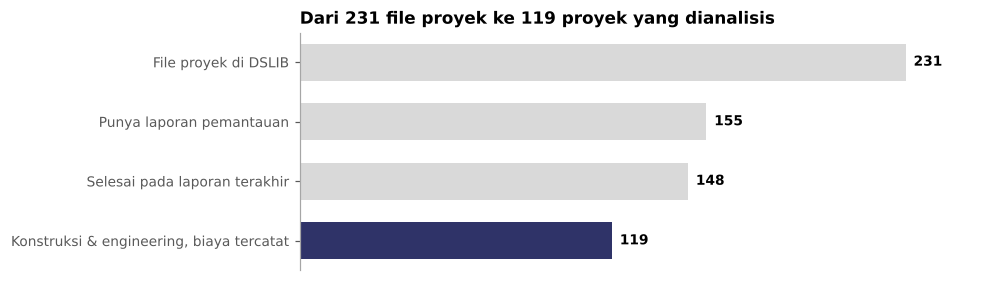

In [8]:
plots.funnel(proyek); plt.savefig(FIG / "01_seleksi_proyek.png"); plt.show()

## 3. Kinerja biaya dan jadwal portofolio
Analisis memakai 119 proyek konstruksi dan engineering yang selesai. Rasio biaya = biaya aktual akhir / anggaran; rasio durasi = durasi aktual / durasi rencana (hari kerja).

In [9]:
a = an.portfolio(proyek)
ringkas = an.summary(a, P)
pd.Series(ringkas).to_frame("nilai").style.format(lambda v: f"{v:.3f}" if isinstance(v, float) else v)

,nilai
proyek,119.000
di_atas_anggaran,0.513
di_bawah_anggaran,0.193
membengkak_material,0.244
terlambat,0.723
median_rasio_biaya,1.007
p80_rasio_biaya,1.058
p90_rasio_biaya,1.161
median_rasio_durasi,1.087
korelasi_biaya_durasi_spearman,0.069


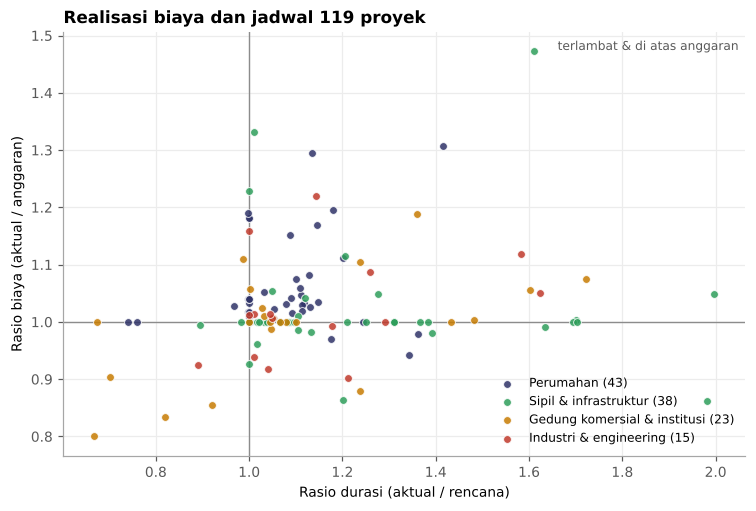

In [10]:
plots.outcome_scatter(a); plt.savefig(FIG / "02_realisasi_biaya_jadwal.png"); plt.show()

Separuh proyek (51%) selesai di atas anggaran dan 72% terlambat, tetapi proyek tipikal hanya meleset tipis (median rasio biaya 1,007). Risikonya ada di ekor distribusi: 1 dari 10 proyek membengkak lebih dari 16%. Korelasi biaya dan durasi hampir nol (Spearman 0,07), artinya proyek yang terlambat tidak otomatis membengkak biayanya, sehingga keduanya perlu dipantau terpisah.

In [11]:
grp = an.by_group(a, "jenis_pekerjaan")
grp["porsi_terlambat"] = a.groupby("jenis_pekerjaan").rasio_durasi.apply(lambda s: (s > 1.005).mean())
grp.style.format({"median_rasio_biaya": "{:.3f}", "p80_rasio_biaya": "{:.3f}", "median_rasio_durasi": "{:.3f}",
                  "porsi_di_atas_anggaran": "{:.0%}", "porsi_terlambat": "{:.0%}"})

,proyek,median_rasio_biaya,p80_rasio_biaya,median_rasio_durasi,porsi_di_atas_anggaran,porsi_terlambat
jenis_pekerjaan,,,,,,
Perumahan,43,1.031,1.099,1.078,79%,60%
Sipil & infrastruktur,38,1.000,1.029,1.127,24%,87%
Gedung komersial & institusi,23,1.000,1.057,1.047,39%,65%
Industri & engineering,15,1.012,1.093,1.050,60%,80%


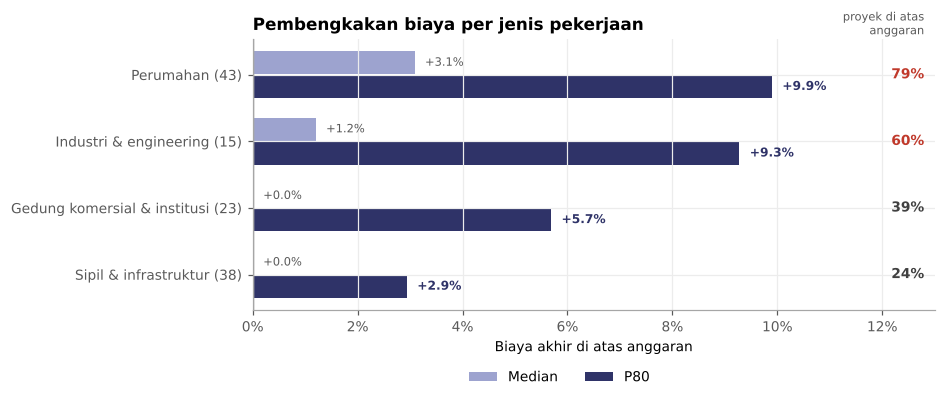

In [12]:
plots.group_bars(an.by_group(a, "jenis_pekerjaan")); plt.savefig(FIG / "03_biaya_per_jenis.png"); plt.show()

In [13]:
an.by_group(a, "kelas_ukuran").style.format({"median_rasio_biaya": "{:.3f}", "p80_rasio_biaya": "{:.3f}",
                                              "median_rasio_durasi": "{:.3f}", "porsi_di_atas_anggaran": "{:.0%}"})

,proyek,median_rasio_biaya,p80_rasio_biaya,median_rasio_durasi,porsi_di_atas_anggaran
kelas_ukuran,,,,,
Kecil (< 250 rb),46,1.006,1.053,1.042,50%
Besar (> 1 jt),38,1.014,1.107,1.096,58%
Menengah (250 rb - 1 jt),35,1.000,1.047,1.105,46%


- **Perumahan** paling sering melampaui anggaran (79% proyek) dengan P80 +9,9%.
- **Sipil & infrastruktur** paling terkendali dari sisi biaya (24% di atas anggaran), tetapi 87% terlambat.
- **Proyek besar** (> 1 juta) punya ekor paling panjang (P80 +10,7%), walaupun mediannya hampir sama dengan proyek kecil.

## 4. Peringatan dini: kapan CPI dan EAC bisa dipercaya?
Untuk setiap proyek diambil periode pertama ketika progres (EV/BAC) mencapai 10, 25, 50, 75, dan 90%. Pada titik itu dinilai dua hal:
1. **Akurasi perkiraan**: apakah EAC = BAC/CPI meleset tidak lebih dari 5% dari biaya aktual akhir, dibanding anggaran awal tanpa koreksi?
2. **Ketepatan sinyal**: apakah CPI < 0,95 menandai proyek yang akhirnya membengkak > 5%?

In [14]:
pp = an.project_periods(periode, a)
snap = an.milestone_snapshots(pp, P)
ew = an.early_warning(snap, P)
ew.style.format({"milestone": "{:.0%}", "eac_dalam_5pct": "{:.0%}", "bac_dalam_5pct": "{:.0%}", "median_galat_eac": "{:.1%}",
                 "median_galat_bac": "{:.1%}", "recall": "{:.0%}", "presisi": "{:.0%}"})

,milestone,proyek,eac_dalam_5pct,bac_dalam_5pct,median_galat_eac,median_galat_bac,proyek_membengkak,proyek_ditandai,tertangkap,recall,presisi
0,10%,105,60%,64%,3.2%,2.9%,27,29,18,67%,62%
1,25%,104,59%,63%,3.7%,2.9%,27,27,19,70%,70%
2,50%,98,79%,62%,1.8%,3.1%,26,30,21,81%,70%
3,75%,73,88%,59%,0.9%,3.1%,21,17,15,71%,88%
4,90%,55,93%,53%,0.6%,4.6%,19,15,14,74%,93%


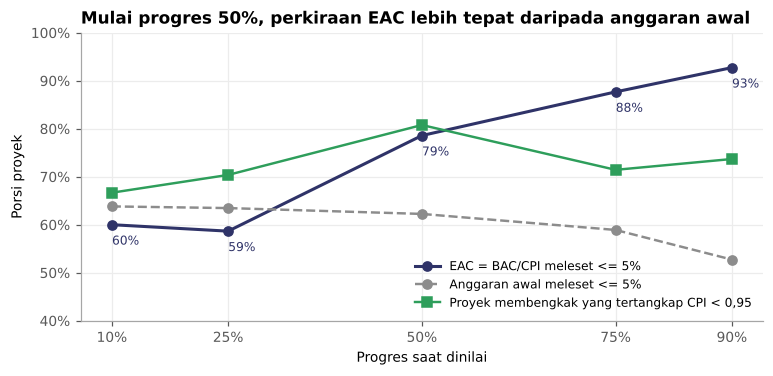

In [15]:
plots.early_warning(ew); plt.savefig(FIG / "04_peringatan_dini.png"); plt.show()

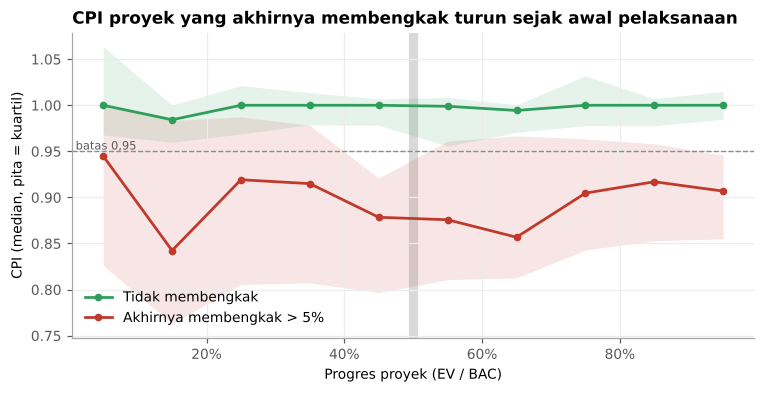

In [16]:
plots.cpi_by_progress(pp, P.overrun_material); plt.savefig(FIG / "05_cpi_per_progres.png"); plt.show()

- Sebelum progres 50%, **EAC belum lebih akurat dari anggaran awal** (60% vs 64% proyek dalam ±5% pada progres 10%). CPI awal masih bergejolak.
- Namun **arah sinyalnya sudah benar sejak awal**: median CPI proyek yang akhirnya membengkak sudah di bawah 0,95.
- Mulai **progres 50%**, EAC meleset maksimal 5% pada 79% proyek (anggaran awal hanya 62%). CPI < 0,95 menangkap 21 dari 26 proyek yang akhirnya membengkak, dan 70% proyek yang ditandai memang membengkak.

Implikasinya: sebelum 50%, CPI dipakai sebagai sinyal tren. Mulai 50%, EAC layak dipakai sebagai perkiraan biaya akhir resmi.

## 5. Produktivitas jam kerja
PF = jam kerja earned / jam kerja aktual untuk sumber daya terbarukan (orang atau alat). Hanya 38 proyek yang mencatat sumber daya, jadi hasil bagian ini indikatif.

In [17]:
b = an.productivity(a)
tb = b.groupby("kelompok_pf").agg(proyek=("kode_proyek", "size"), rata_rasio_durasi=("rasio_durasi", "mean"),
                                  rata_rasio_biaya=("rasio_biaya", "mean"),
                                  terlambat=("rasio_durasi", lambda s: (s > 1.005).mean()))
print("Korelasi Spearman PF vs rasio durasi:", round(b[["pf_tenaga_kerja", "rasio_durasi"]].corr("spearman").iloc[0, 1], 2),
      "| PF vs rasio biaya:", round(b[["pf_tenaga_kerja", "rasio_biaya"]].corr("spearman").iloc[0, 1], 2))
tb.loc[["Di bawah 0,90", "0,90 - 0,99", "1,00 ke atas"]].style.format(
    {"rata_rasio_durasi": "{:.3f}", "rata_rasio_biaya": "{:.3f}", "terlambat": "{:.0%}"})

Korelasi Spearman PF vs rasio durasi: -0.37 | PF vs rasio biaya: -0.17


,proyek,rata_rasio_durasi,rata_rasio_biaya,terlambat
kelompok_pf,,,,
"Di bawah 0,90",12,1.284,1.036,92%
"0,90 - 0,99",15,1.070,1.002,80%
"1,00 ke atas",11,1.158,1.006,73%


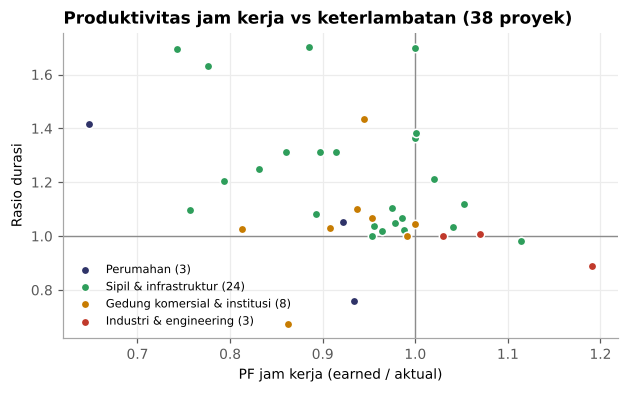

In [18]:
plots.productivity(b); plt.savefig(FIG / "06_produktivitas.png"); plt.show()

Proyek dengan PF di bawah 0,90 rata-rata selesai 28% lebih lama dari rencana, jauh di atas dua kelompok lain (7% dan 16%), dan 92% di antaranya terlambat. Hubungan PF dengan biaya lebih lemah (Spearman −0,17 dibanding −0,37 untuk durasi), sehingga produktivitas jam kerja terutama menjadi indikator risiko jadwal. Polanya tidak linear dan sampelnya kecil, jadi hasil ini adalah sinyal untuk dipantau, bukan model prediksi.

## 6. Kelas referensi untuk estimasi tender
Prinsip *reference class forecasting*: kontinjensi proyek baru diambil dari distribusi rasio biaya proyek historis yang sejenis. Faktor P80 berarti 80% proyek historis sejenis selesai dengan biaya akhir tidak lebih dari estimasi × faktor.

In [19]:
rc = an.reference_classes(a)
rc.style.format({"P50": "{:.3f}", "P80": "{:.3f}", "P90": "{:.3f}"})

,dimensi,kelas,proyek,P50,P80,P90
0,Semua proyek,Semua,119,1.007,1.058,1.161
1,Jenis pekerjaan,Gedung komersial & institusi,23,1.000,1.057,1.098
2,Jenis pekerjaan,Industri & engineering,15,1.012,1.093,1.142
3,Jenis pekerjaan,Perumahan,43,1.031,1.099,1.182
4,Jenis pekerjaan,Sipil & infrastruktur,38,1.000,1.029,1.072
5,Ukuran proyek,Besar (> 1 jt),38,1.014,1.107,1.202
6,Ukuran proyek,Kecil (< 250 rb),46,1.006,1.053,1.170
7,Ukuran proyek,Menengah (250 rb - 1 jt),35,1.000,1.047,1.069


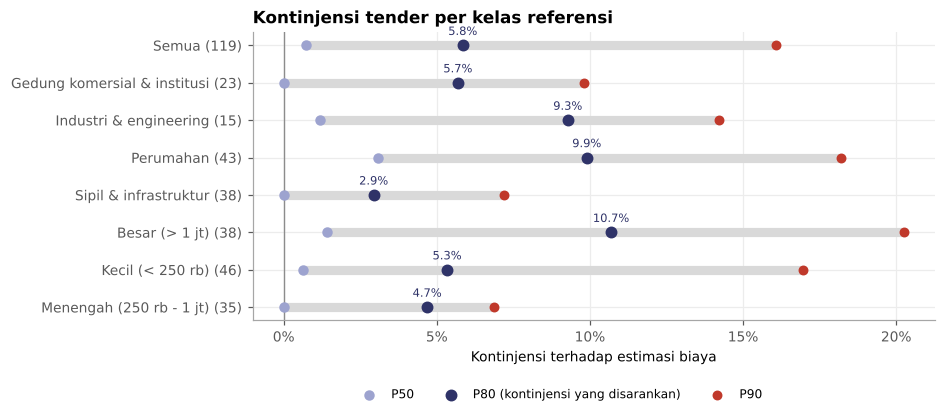

In [20]:
plots.reference_classes(rc); plt.savefig(FIG / "07_kelas_referensi.png"); plt.show()

**Uji mundur leave-one-out.** Untuk setiap proyek, faktor dihitung dari proyek lain saja (seolah proyek itu sedang ditenderkan), lalu dicek apakah biaya aktualnya tertutup. Bila kelas berisi kurang dari 10 proyek, dipakai kelas semua proyek.

In [21]:
bt = pd.DataFrame([an.loo_backtest(a, c, lv) for c in [None, "jenis_pekerjaan", "kelas_ukuran"] for lv in an.LEVELS])
bt.pivot(index="kelas", columns="level", values="cakupan").style.format("{:.0%}")

level,0.500000,0.800000,0.900000
kelas,,,
Semua proyek,50%,79%,89%
jenis_pekerjaan,58%,77%,88%
kelas_ukuran,50%,78%,88%


Cakupan aktual mendekati target (P80 menutup 77–79% proyek, P90 88–89%), sehingga faktor ini terkalibrasi baik dan tidak terlalu optimistis. Contoh: estimasi biaya 2,5 juta untuk proyek industri & engineering dengan keyakinan P80.

In [22]:
est = 2_500_000
f80 = rc.set_index("kelas").loc["Industri & engineering", "P80"]
print(f"Faktor P80: {f80:.3f} -> kontinjensi {est * (f80 - 1):,.0f}; biaya + kontinjensi {est * f80:,.0f}; "
      f"harga dengan margin {P.margin:.0%}: {est * f80 * (1 + P.margin):,.0f}")

Faktor P80: 1.093 -> kontinjensi 231,872; biaya + kontinjensi 2,731,872; harga dengan margin 10%: 3,005,060


## 7. Skenario margin
Data sumber tidak memuat nilai kontrak. Sebagai skenario, nilai kontrak = anggaran biaya × (1 + margin), dan margin realisasi = 1 − biaya aktual akhir / nilai kontrak.

In [23]:
ms = an.margin_scenario(a)
ms.style.format({"margin_rencana": "{:.0%}", "median_margin_realisasi": "{:.1%}", "porsi_rugi": "{:.0%}",
                 "porsi_margin_tergerus_separuh": "{:.0%}"})

,margin_rencana,median_margin_realisasi,proyek_rugi,porsi_rugi,porsi_margin_tergerus_separuh
0,5%,4.1%,29,24%,38%
1,8%,6.7%,21,18%,31%
2,10%,8.4%,19,16%,27%
3,12%,10.1%,14,12%,24%
4,15%,12.4%,14,12%,19%


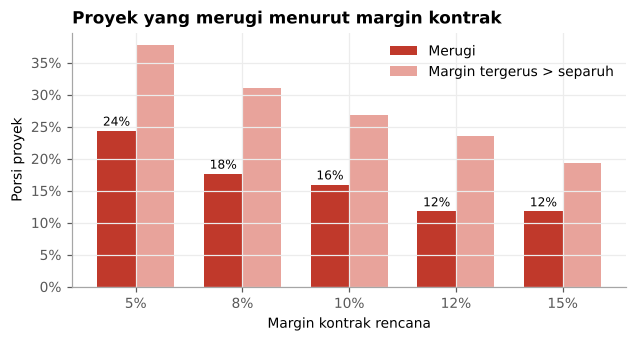

In [24]:
plots.margin(ms); plt.savefig(FIG / "08_skenario_margin.png"); plt.show()

Dengan margin 10%, 16% proyek historis akan merugi dan 27% kehilangan lebih dari separuh margin. Menaikkan margin dari 10% ke 12% menurunkan porsi proyek rugi dari 16% ke 12%. Itulah nilai kontinjensi yang dihitung dari data.

## 8. Contoh laporan status: C2011-13 Wind Farm
Proyek industri dengan 120 laporan mingguan. Biaya akhirnya 22% di atas anggaran. CPI jatuh tajam pada awal 2010, ketika pekerjaan utama dimulai, dan tidak pernah pulih di atas 0,95.

Progres 50% tercapai pada periode 99 (12-09-2010): CPI 0.81, EAC 26,452,110 vs biaya aktual akhir 26,077,765 (selisih +1.4%); anggaran awal 21,369,836 (selisih -18.1%)


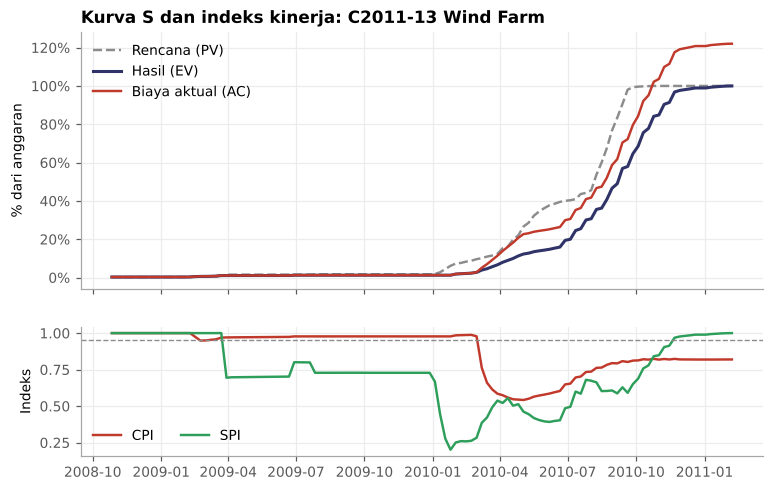

In [25]:
k = "C2011-13"
g = pp[pp.kode_proyek == k]
bac = a.set_index("kode_proyek").loc[k, "bac"]
plots.s_curve(g, "C2011-13 Wind Farm", bac); plt.savefig(FIG / "09_kurva_s_contoh.png"); plt.show()
m50 = g[(g.progres >= 0.5) & (g.progres < 0.9999)].iloc[0]
print(f"Progres 50% tercapai pada periode {int(m50.periode)} ({m50.tanggal_status:%d-%m-%Y}): CPI {m50.cpi:.2f}, "
      f"EAC {m50.eac_cpi:,.0f} vs biaya aktual akhir {g.ac.iloc[-1]:,.0f} (selisih {m50.eac_cpi / g.ac.iloc[-1] - 1:+.1%}); "
      f"anggaran awal {bac:,.0f} (selisih {bac / g.ac.iloc[-1] - 1:+.1%})")

## 9. SQL dan konsistensi dengan Excel
Tabel olahan dimuat ke SQLite (`sql/schema.sql`), lalu kueri di `sql/analysis.sql` dijalankan. Hasilnya harus sama dengan pandas.

In [26]:
dbp = db.build_database(ROOT)
q = db.queries(ROOT)
print("Kueri:", ", ".join(q))
db.run(dbp, q["kinerja_per_jenis"])

Kueri: ringkasan_portofolio, kinerja_per_jenis, status_terakhir, peringatan_dini_50, produktivitas, rekonsiliasi_ringkasan


,jenis_pekerjaan,proyek,median_rasio_biaya,p80_rasio_biaya,porsi_di_atas_anggaran
0,Perumahan,43,1.030841,1.098955,0.790698
1,Sipil & infrastruktur,38,1.000000,1.029374,0.236842
2,Gedung komersial & institusi,23,1.000000,1.056863,0.391304
3,Industri & engineering,15,1.011988,1.092749,0.600000


In [27]:
sql_ew = db.run(dbp, q["peringatan_dini_50"]).iloc[0]
py_ew = ew[ew.milestone == 0.5].iloc[0]
pd.DataFrame({"SQL": sql_ew[["proyek", "proyek_membengkak", "proyek_ditandai", "tertangkap", "eac_dalam_5pct"]],
              "pandas": py_ew[["proyek", "proyek_membengkak", "proyek_ditandai", "tertangkap", "eac_dalam_5pct"]]})

,SQL,pandas
proyek,98.000000,98.000000
proyek_membengkak,26.000000,26.000000
proyek_ditandai,30.000000,30.000000
tertangkap,21.000000,21.000000
eac_dalam_5pct,0.785714,0.785714


Angka kunci workbook Excel (formula, dihitung ulang) dibandingkan dengan Python. Pengujian lengkap ada di `tests/test_excel_parity.py`.

In [28]:
from openpyxl import load_workbook
wb = load_workbook(ROOT / "excel" / "Analisis_Kinerja_Biaya_Jadwal_Proyek.xlsx", data_only=True)
K, W, R = wb["Kinerja_Portofolio"], wb["Peringatan_Dini"], wb["Kelas_Referensi"]
rck = rc.set_index("kelas")
cek = [("Proyek dianalisis", ringkas["proyek"], K["C7"].value),
       ("Di atas anggaran", ringkas["di_atas_anggaran"], K["C8"].value),
       ("Terlambat", ringkas["terlambat"], K["C11"].value),
       ("P80 rasio biaya", ringkas["p80_rasio_biaya"], K["C13"].value),
       ("EAC dalam 5% @50%", py_ew.eac_dalam_5pct, W["E9"].value),
       ("Recall CPI @50%", py_ew.recall, W["J9"].value)] + \
      [(f"P80 {R[f'B{r}'].value}", rck.loc[R[f"B{r}"].value, "P80"], R[f"F{r}"].value) for r in range(6, 14)]
par = pd.DataFrame(cek, columns=["angka", "python", "excel"])
par["selisih"] = (par.python.astype(float) - par.excel.astype(float)).abs()
print(f"{(par.selisih < 1e-5).sum()} dari {len(par)} angka sama (selisih < 0,00001)")
par

14 dari 14 angka sama (selisih < 0,00001)


,angka,python,excel,selisih
0,Proyek dianalisis,119.000000,119.000000,0.000000e+00
1,Di atas anggaran,0.512605,0.512605,3.330669e-16
2,Terlambat,0.722689,0.722689,1.110223e-16
3,P80 rasio biaya,1.058472,1.058472,9.714007e-11
4,EAC dalam 5% @50%,0.785714,0.785714,3.330669e-16
5,Recall CPI @50%,0.807692,0.807692,3.330669e-16
6,P80 Semua,1.058472,1.058472,9.714007e-11
7,P80 Perumahan,1.098955,1.098955,3.135048e-09
8,P80 Sipil & infrastruktur,1.029374,1.029374,1.735277e-09
9,P80 Gedung komersial & institusi,1.056863,1.056863,2.708238e-09


Selisih yang sangat kecil (< 10⁻⁵) berasal dari pembulatan 2 desimal di file laporan status yang dibaca Excel lewat Power Query.

## 10. Rekomendasi
1. **Review biaya wajib pada progres 50%.** Proyek dengan CPI < 0,95 masuk daftar tindak lanjut, dan EAC = BAC/CPI dipakai sebagai perkiraan biaya akhir resmi.
2. **Sebelum progres 50%**, laporkan CPI sebagai sinyal tren, bukan dasar revisi anggaran.
3. **Kontinjensi tender** memakai faktor P80 per jenis pekerjaan: perumahan +9,9%, industri & engineering +9,3%, gedung +5,7%, sipil +2,9%. Gunakan kelas "semua proyek" (+5,8%) bila data kelas kurang dari 10 proyek.
4. **Perhatian khusus untuk perumahan dan proyek besar**, yang punya ekor pembengkakan paling panjang.
5. **Standarkan laporan status site** (kolom, desimal, tanggal) dan wajibkan pencatatan jam kerja aktual. Saat ini hanya 38 dari 119 proyek yang punya data produktivitas.

**Keterbatasan**
- Proyek DSLIB sebagian besar konstruksi di Belgia, ditambah proyek sipil di Peru. Belum ada proyek pertambangan atau migas, sehingga faktor kontinjensi perlu dikalibrasi ulang dengan data internal perusahaan. Metodenya tetap sama.
- Nilai kontrak tidak tersedia, jadi analisis margin adalah skenario.
- Kelas industri & engineering hanya berisi 15 proyek, sehingga persentilnya lebih tidak stabil.
- Durasi aktual dihitung sampai tanggal status terakhir, mengikuti definisi ringkasan DSLIB.

**Sumber data:** Batselier, J. & Vanhoucke, M. (2015). Construction and evaluation framework for a real-life project database. *International Journal of Project Management*, 33(3), 697–710. Data: DSLIB, OR&S Research Group, Ghent University (github.com/MarioVanhoucke/DSLIB-Dynamic-Scheduling-Empirical-Project-Library).